In [2]:

from Influence_Modelling import XsvNetwork, Network, Sampling, Metrics, Heuristics
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import scienceplots 
plt.style.use(["science", "no-latex"])
import time

In [3]:
enron  =XsvNetwork.XsvNetwork("enron")
net = Network.Network("")
net.set_nx(Sampling.mhda_sample(enron.get_nx(), 1000))

In [112]:
print(net.get_nx())

Graph with 1000 nodes and 5440 edges


In [113]:
com = nx.community.greedy_modularity_communities(net.get_nx(), best_n=14)

In [118]:
def community_heuristic(G, communities, n):
  # com is a list of nodes in each community
  #print([len(x) for x in communities])
  coms = communities[0:4]
  #print([len(com) for com in coms])
  nodes_selected = np.zeros(len(coms))
  #print(nodes_selected)
  #print(list(coms[0]))
  subgraphs = [G.subgraph(list(x)).copy() for x in coms]
  selected=  set()
  while len(selected) < n:
    to_choose_index = np.argmin(nodes_selected)
    found_nodes = Heuristics.double_deg_discount_h(subgraphs[to_choose_index], nodes_selected[to_choose_index] + 5)
    [selected.add(x) for x in found_nodes]
    nodes_selected[to_choose_index] += len(found_nodes)
  return list(selected)

In [119]:
sel = community_heuristic(net.get_nx(), com, 100)

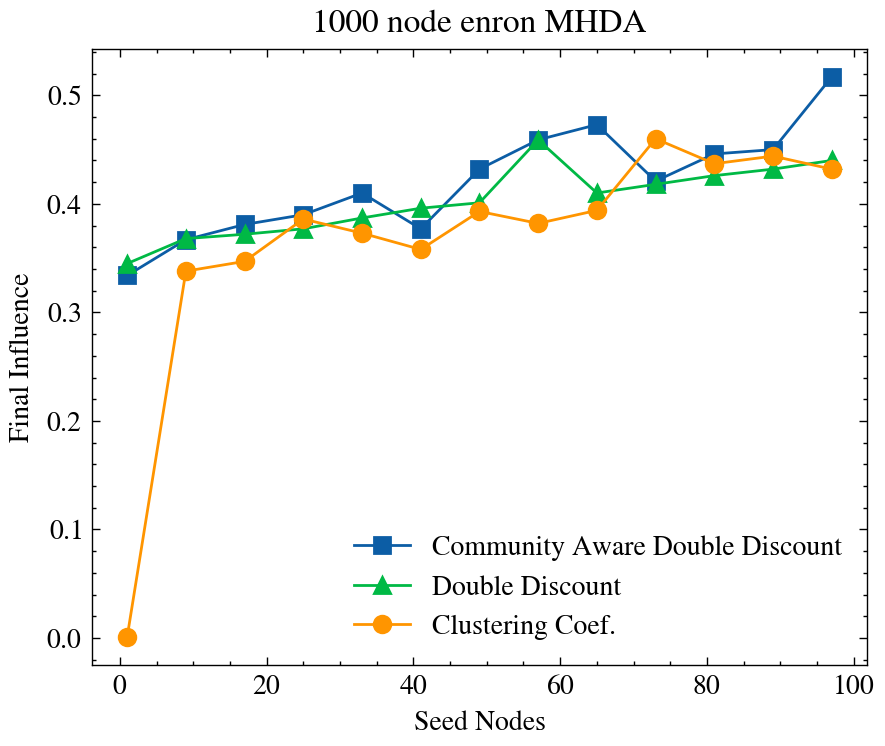

In [130]:
sizes = [x for x in range(1, 100, 8)]

a = time.time_ns()
deg = [net.run_ICC(Heuristics.double_deg_discount_h(net.get_nx(), size)) for size in sizes]
deg = [de[2][-1] for de in deg]
b = time.time_ns()

whaterver = [net.run_ICC(community_heuristic(net.get_nx(), com, size)) for size in sizes]
whaterver = [de[2][-1] for de in whaterver]
c = time.time_ns()

bet = [net.run_ICC(Heuristics.local_clustering_coefficient_h(net.get_nx(), size)) for size in sizes]
bet = [de[2][-1] for de in bet]
d = time.time_ns()

fig, ax = plt.subplots()
fig.set_size_inches(5,4)
fig.set_dpi(200)
ax.plot(sizes, whaterver, label="Community Aware Double Discount", marker="s")
ax.plot(sizes, deg, label="Double Discount", marker="^")
ax.plot(sizes, bet, label="Clustering Coef.", marker="o")
ax.set_xlabel("Seed Nodes")
ax.set_ylabel("Final Influence")
ax.set_title("1000 node enron MHDA")
ax.legend()

In [136]:
print(f"Time for Double Discount: {(b - a)/1000/1000}ms")
print(f"Time for Double Discount Community: {(c-b)/1000/1000}ms")
print(f"Time for Local Clustering: {(d-c)/1000/1000}ms")

Time for Double Discount: 444.089895ms
Time for Double Discount Community: 1459.316874ms
Time for Local Clustering: 844.340475ms


In [8]:
communities = []
for k in range(1, 50):
  coms = nx.community.greedy_modularity_communities(net.get_nx(), best_n=k)
  communities.append(coms)

In [10]:
print([[len(c) for c in com] for com in communities])

[[1000], [999, 1], [997, 2, 1], [995, 2, 2, 1], [993, 2, 2, 2, 1], [990, 3, 2, 2, 2, 1], [618, 372, 3, 2, 2, 2, 1], [376, 372, 242, 3, 2, 2, 2, 1], [372, 262, 242, 114, 3, 2, 2, 2, 1], [372, 242, 196, 114, 66, 3, 2, 2, 2, 1], [372, 242, 162, 114, 66, 34, 3, 2, 2, 2, 1], [359, 242, 162, 114, 66, 34, 13, 3, 2, 2, 2, 1], [359, 221, 162, 114, 66, 34, 21, 13, 3, 2, 2, 2, 1], [344, 221, 162, 114, 66, 34, 21, 15, 13, 3, 2, 2, 2, 1], [336, 221, 162, 114, 66, 34, 21, 15, 13, 8, 3, 2, 2, 2, 1], [328, 221, 162, 114, 66, 34, 21, 15, 13, 8, 8, 3, 2, 2, 2, 1], [322, 221, 162, 114, 66, 34, 21, 15, 13, 8, 8, 6, 3, 2, 2, 2, 1], [311, 221, 162, 114, 66, 34, 21, 15, 13, 11, 8, 8, 6, 3, 2, 2, 2, 1], [304, 221, 162, 114, 66, 34, 21, 15, 13, 11, 8, 8, 7, 6, 3, 2, 2, 2, 1], [304, 221, 162, 66, 59, 55, 34, 21, 15, 13, 11, 8, 8, 7, 6, 3, 2, 2, 2, 1], [304, 214, 162, 66, 59, 55, 34, 21, 15, 13, 11, 8, 8, 7, 7, 6, 3, 2, 2, 2, 1], [304, 205, 162, 66, 59, 55, 34, 21, 15, 13, 11, 9, 8, 8, 7, 7, 6, 3, 2, 2, 2, 1], [

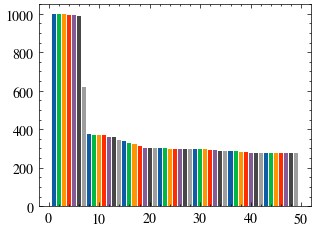

In [ ]:
import matplotlib.pyplot as plt
a = [[len(c) for c in com] for com in communities]
b = range(1, 50)
for j in range(len(a)):
  plt.bar(b[j], a[j])
